# Server Anomaly Detection with LSTM and GRU Autoencoder

**Project goal:** Use historical server KPIs to **detect anomalous observations** in the Server Machine Dataset (SMD). This project focuses on **anomaly detection, not future incident prediction**.

The source dataset is the [OmniAnomaly ServerMachineDataset](https://github.com/NetManAIOps/OmniAnomaly/tree/master/ServerMachineDataset).


We compare two unsupervised neural networks: an **LSTM Autoencoder** and a **GRU Autoencoder**.

### Workflow

1. **Load & visualize data**
2. **Preprocess & split by time**
3. **Create sliding windows**
4. **Train the two Autoencoders**
5. **Calculate reconstruction errors**
6. **Set a threshold**
7. **Evaluate and visualize detection results**

**Important distinction:**
- Training does not need anomaly labels: the model learns to reconstruct the KPI sequences. 
- Labels from `test_label` are used **only to evaluate** the final predictions.

**SMD limitations:** 
- The 38 metrics are anonymized, the data are sequenced but no timestamps provided. 
- Labels describe anomalies, not verified service outages.


## Configuration and Libraries

The settings below control the experiment. Start with **one machine, one random seed, and two models**. This makes the notebook easy to follow and avoids unnecessary hyperparameter experiments.
The initial setting.
- **WINDOW = 60:** 60 consecutive observations form one training sample.
- **UNITS = 64:** LSTM/GRU hidden-state size.
- **LATENT = 16:** size of the compressed representation.
- **THRESHOLD_PERCENTILE = 99:** an initial, fixed threshold rule based on calibration errors. 

To adjust the traing/predict result tune the hpyerparameters to achieve difference result.

In [10]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------- Experiment settings ----------------
MACHINE = "machine-1-1"
DATA_DIR = Path("ServerMachineDataset")  # Preferred: official train/, test/, test_label/ folders

WINDOW_SIZE = 60            # Number of time steps per sample
UNITS = 64                  # Hidden units in each LSTM/GRU layer
LATENT = 16                 # Latent vector dimension
EPOCHS = 20                 # Maximum training epochs
TRAIN_BATCH = 32            # Windows per training update
PREDICT_BATCH = 128         # Windows processed per prediction batch
LEARNING_RATE = 0.001       # Learning rate for the optimizer
PATIENCE = 5                # Early stopping patience
THRESHOLD_PERCENTILE = 99
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})
print("Notebook location:", Path.cwd())

Notebook location: /Users/jackzhang/Documents/UofT/Deep Learning Project-Anomaly_Detection_RNN


## Load the SMD Dataset

Every row represents **one observation**. The original 38 columns are **KPI features**. The train and test arrays have the same columns; only the test set has supplied anomaly labels (`0 = normal`, `1 = anomaly`).

The files are under folder of train,test,and test_label


In [11]:
# Locate data files
train_path = DATA_DIR / "train" / f"{MACHINE}.txt"
test_path = DATA_DIR / "test" / f"{MACHINE}.txt"
label_path = DATA_DIR / "test_label" / f"{MACHINE}.txt"
print("train_path:", train_path)
print("test_path:", test_path)
print("label_path:", label_path)    

for path in [train_path, test_path, label_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}. Place the SMD files next to this notebook.")

# Read data (no column headers)
train_raw = np.loadtxt(train_path, delimiter=",", dtype=np.float32)
test_raw = np.loadtxt(test_path, delimiter=",", dtype=np.float32)
test_label = np.loadtxt(label_path, dtype=np.int32)

# Basic checks
# ensure the number of KPIs (features) is consistent across train and test sets
assert train_raw.shape[1] == test_raw.shape[1] == 38 
# make sure the number of test samples matches the number of labels
assert len(test_raw) == len(test_label) 
#assert set(np.unique(test_label)).issubset({0, 1})
# 确保 KPI 数据中没有 NaN、正无穷或负无穷值，避免模型训练出现无效的 Loss
assert np.isfinite(train_raw).all() and np.isfinite(test_raw).all() 

print("\nTraining KPIs:", train_raw.shape)
print("Testing KPIs: ", test_raw.shape)
print("Test labels:  ", test_label.shape)
print("Anomaly observations:", int(test_label.sum()), "of", len(test_label))

# Give each KPI feature a readable name for display, and print sample rows of the training data
columns = [f"KPI {i + 1}" for i in range(train_raw.shape[1])]
display(pd.DataFrame(train_raw[:5], columns=columns).iloc[:, :10])

train_path: ServerMachineDataset/train/machine-1-1.txt
test_path: ServerMachineDataset/test/machine-1-1.txt
label_path: ServerMachineDataset/test_label/machine-1-1.txt

Training KPIs: (28479, 38)
Testing KPIs:  (28479, 38)
Test labels:   (28479,)
Anomaly observations: 2694 of 28479


,KPI 1,KPI 2,KPI 3,KPI 4,KPI 5,KPI 6,KPI 7,KPI 8,KPI 9,KPI 10
0,0.032258,0.039195,0.027871,0.024390,0.0,0.915385,0.343691,0.0,0.020011,0.000122
1,0.043011,0.048729,0.033445,0.025552,0.0,0.915385,0.344633,0.0,0.019160,0.001722
2,0.043011,0.034958,0.032330,0.025552,0.0,0.915385,0.344633,0.0,0.020011,0.000122
3,0.032258,0.028602,0.030100,0.024390,0.0,0.912821,0.342750,0.0,0.021289,0.000000
4,0.032258,0.019068,0.026756,0.023229,0.0,0.912821,0.342750,0.0,0.018734,0.000000


## Explore the Dataset (Real Observations)

We first visualize what the server measurements look like **before** building a model.

- The first plot shows the numbers of normal and anomalous **test observations**.
- The second plot shows three example KPIs over time. **Red shaded regions** are the official test anomaly labels.
- Labels are used here only to **understand and visualize the dataset**, not to choose model inputs or tune a threshold.


Number of labeled anomaly periods: 8
Anomaly rows (%): 9.46
Periods [start, end): [(15849, 16395), (16963, 17517), (18071, 18528), (19367, 20088), (20786, 21195), (24679, 24682), (26114, 26116), (27554, 27556)]


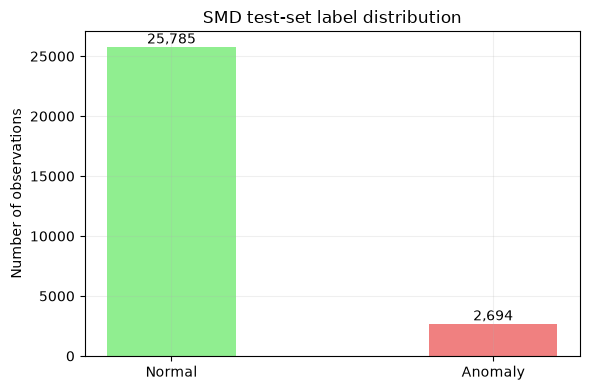

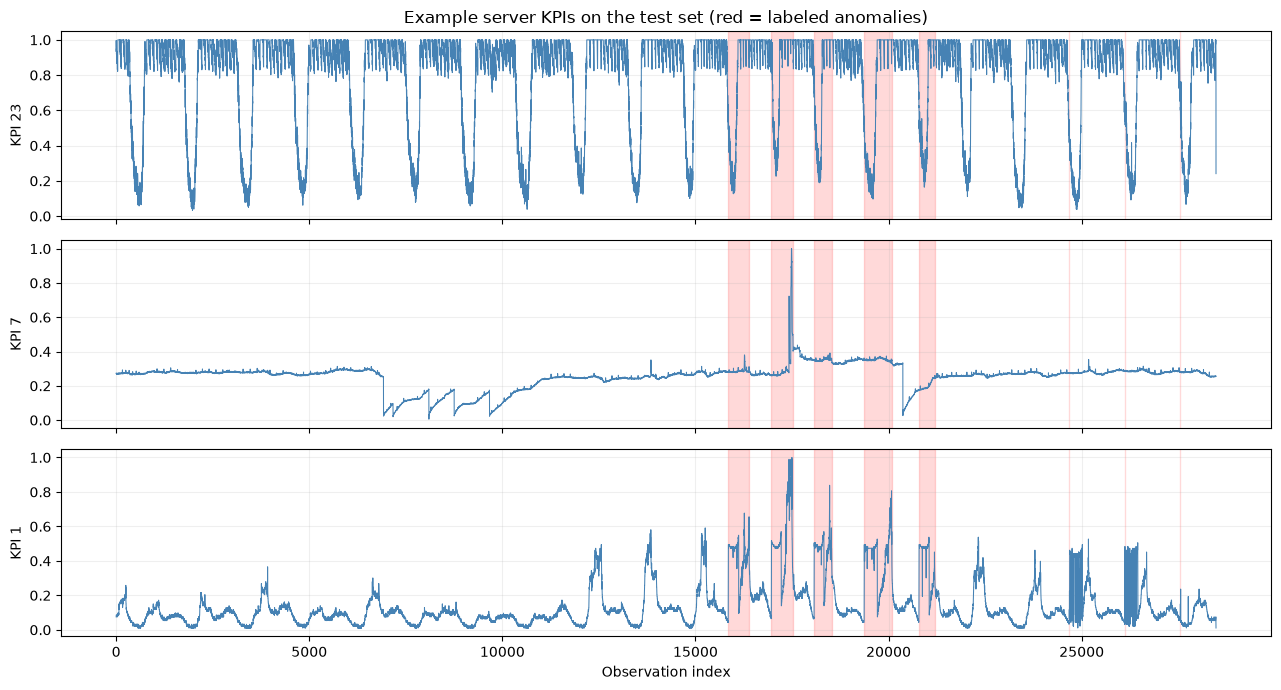

In [12]:
# Find continuous periods where the official label equals 1 (anomalous)
def find_anomaly_periods(labels):
    periods = []
    start = None

    for index, label in enumerate(labels):
        if label == 1 and start is None:
            start = index
        elif label == 0 and start is not None:
            periods.append((start, index))  # End index is excluded
            start = None

    if start is not None:
        periods.append((start, len(labels)))

    return periods

anomaly_periods = find_anomaly_periods(test_label)
print("Number of labeled anomaly periods:", len(anomaly_periods))
print("Anomaly rows (%):", round(test_label.mean() * 100, 2))
print("Periods [start, end):", anomaly_periods)

# Plot the number of normal and anomalous observations
counts = [int((test_label == 0).sum()), int((test_label == 1).sum())]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Normal", "Anomaly"], counts, width=0.4, color=["lightgreen", "lightcoral"])
ax.set_ylabel("Number of observations")
ax.set_title("SMD test-set label distribution")
for index, count in enumerate(counts):
    ax.text(index, count, f"{count:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Pick three example features using TRAIN variability only (no test labels)
example_features = np.argsort(train_raw.std(axis=0))[-3:][::-1]

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for ax, feature in zip(axes, example_features):
    ax.plot(test_raw[:, feature], linewidth=0.75, color="steelblue")
    for start, end in anomaly_periods:
        ax.axvspan(start, end, color="red", alpha=0.15)
    ax.set_ylabel(f"KPI {feature + 1}")
axes[0].set_title("Example server KPIs on the test set (red = labeled anomalies)")
axes[-1].set_xlabel("Observation index")
plt.tight_layout()
plt.show()

## Preprocess and Split the Training Series

We remove **constant KPI columns**, because a feature that never changes provides little useful temporal information.

The official **training series** is then split **Sequentially** into three nonoverlapping parts:

| Section | Approximate proportion | Used for |
|---|---:|---|
| Training | 70% | Update model weights |
| Validation | 15% | Early stopping |
| Calibration | 15% | Determine anomaly threshold |

The official **test series remains untouched** until final evaluation. SMD values are already normalized; no extra scaler is applied in this simple baseline.


In [13]:
# Split the official training series chronologically, BEFORE fitting preprocessing.
train_end = int(len(train_raw) * 0.70)
validation_end = int(len(train_raw) * 0.85)

# decide which KPI columns are constant
keep_columns = train_raw[:train_end].std(axis=0) > 1e-8
train = train_raw[:, keep_columns]
test = test_raw[:, keep_columns]
n_features = train.shape[1]

# split the training data into train, validation, and calibration sets
train_data = train[:train_end]
val_data = train[train_end:validation_end]
cal_data = train[validation_end:]

print("Removed constant features:", int((~keep_columns).sum()))
print("Remaining features:", n_features)
print(
    f"Rows -> Train: {len(train_data):,} | "
    f"Val: {len(val_data):,} | "
    f"Cal: {len(cal_data):,} | "
    f"Test: {len(test):,}"
)


Removed constant features: 8
Remaining features: 30
Rows -> Train: 19,935 | Val: 4,272 | Cal: 4,272 | Test: 28,479


## Create Sliding Windows

A model input is not one row. It is a **window of consecutive rows**, each containing the remaining KPI features.

`rows 0–WINDOW_SIZE-1 → Window 1`, `rows 1–WINDOW_SIZE → Window 2`, `rows 2–WINDOW_SIZE+1 → Window 3`, etc.

Each window has shape `(WINDOW_SIZE, n_features)`. Training samples are shuffled **by complete windows**, while the WINDOW_SIZE observations **inside each window stay in order**.

To avoid overlapping information across dataset partitions, we create windows **separately** within training, validation, calibration and test. 

In [14]:
from numpy.lib.stride_tricks import sliding_window_view


def make_windows(data, window_size):
    windows = sliding_window_view(data, window_shape=window_size, axis=0)
    # sliding_window_view returns (num_windows, features, window_size)
    # We want (num_windows, window_size, features)
    # so swap the last two axes so the shape is (number of windows, w, number of metrics)
    windows = np.swapaxes(windows, 1, 2)
    return windows.copy()


W_TRAIN = make_windows(train_data, WINDOW_SIZE)
W_VAL = make_windows(val_data, WINDOW_SIZE)
W_CAL = make_windows(cal_data, WINDOW_SIZE)
W_TEST = make_windows(test, WINDOW_SIZE)

# The score for each test window belongs to its final observation.
y_true = test_label[WINDOW_SIZE - 1:]
assert len(W_TEST) == len(y_true)

print("Training windows:", W_TRAIN.shape)
print("Validation windows:", W_VAL.shape)
print("Calibration windows:", W_CAL.shape)
print("Test windows:", W_TEST.shape)
print("Aligned test labels:", y_true.shape)

Training windows: (19876, 60, 30)
Validation windows: (4213, 60, 30)
Calibration windows: (4213, 60, 30)
Test windows: (28420, 60, 30)
Aligned test labels: (28420,)


## Build and Train LSTM / GRU Autoencoders

Both models are trained with the same hyperparameters. Since this is an **Autoencoder**, the **target is the input itself**: `model.fit(W_TRAIN, W_TRAIN)`.

During training, the model:

1. Reconstructs the input windows.
2. Computes **mean squared error (MSE)** between original and reconstructed values.
3. Uses backpropagation to update model weights after each training batch.
4. Stops if validation loss has not improved for several epochs.


In [15]:
# Import TensorFlow only where training begins.
# If unavailable, install it into this notebook's Python environment first.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)


def build_autoencoder(model_type):
    # Choose the recurrent cell type
    if model_type == "LSTM":
        RNN = layers.LSTM
    elif model_type == "GRU":
        RNN = layers.GRU
    else:
        raise ValueError("Model type must be 'LSTM' or 'GRU'")

    inputs = layers.Input(shape=(WINDOW_SIZE, n_features))
    encoded = RNN(UNITS)(inputs)                  # Learn the history
    latent = layers.Dense(LATENT)(encoded)        # Compress into a latent vector
    repeated = layers.RepeatVector(WINDOW_SIZE)(latent)
    decoded = RNN(UNITS, return_sequences=True)(repeated)
    outputs = layers.Dense(n_features)(decoded)  # Reconstruct each KPI

    model = keras.Model(inputs, outputs, name=f"{model_type.lower()}_autoencoder")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse"
    )
    return model


# Inspect both network sizes before training
for name in ["LSTM", "GRU"]:
    sample_model = build_autoencoder(name)
    print(f"{name}: {sample_model.count_params():,} trainable parameters")
    sample_model.summary()   # Display detailed layer information for each model






LSTM: 48,046 trainable parameters


2026-11-21 23:54:20.857421: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-21 23:54:20.857460: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-11-21 23:54:20.857467: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
I0000 00:00:1795323260.857629 10340600 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1795323260.857770 10340600 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "lstm_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 30)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 60, 30)         │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,046 (187.68 KB)

 Trainable params: 48,046 (187.68 KB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60, 30)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 60, 64)         │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 60, 30)         │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,166 (145.18 KB)

 Trainable params: 37,166 (145.18 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Train each model once with predefined hyperparameters. 
models = {}
histories = {}
training_results = []

for name in ["LSTM", "GRU"]:
    print(f"\nTraining {name} Autoencoder...")

    keras.utils.set_random_seed(SEED)  # Reproducibility
    model = build_autoencoder(name)

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = model.fit(
        W_TRAIN, W_TRAIN,                 # Input and target are the same
        validation_data=(W_VAL, W_VAL),
        epochs=EPOCHS,
        batch_size=TRAIN_BATCH,
        shuffle=True,                    # Shuffle full windows, not their time steps
        callbacks=[early_stop],
        verbose=1
    )

    models[name] = model
    histories[name] = history.history
    training_results.append({
        "Model": name,
        "Epochs": len(history.history["loss"]),
        "Best validation MSE": min(history.history["val_loss"]),
        "Parameters": model.count_params()
    })

display(pd.DataFrame(training_results).round(6))


Training LSTM Autoencoder...
Epoch 1/20


2026-11-21 23:54:21.665685: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


622/622 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - loss: 0.0014 - val_loss: 5.5278e-04
Epoch 2/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 4.0220e-04 - val_loss: 5.2219e-04
Epoch 3/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 3.7525e-04 - val_loss: 4.8958e-04
Epoch 4/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.5545e-04 - val_loss: 4.5998e-04
Epoch 5/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.4551e-04 - val_loss: 4.5425e-04
Epoch 6/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.4023e-04 - val_loss: 4.5759e-04
Epoch 7/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.3624e-04 - val_loss: 4.3618e-04
Epoch 8/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.3332e-04 - val_loss: 4.2332e-04
Epoch 9/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.3134e-04 - val_loss: 4.2452e-04
Epoch 10/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 3.2994e-04 - val_loss: 4.2909e-04
Epoch 11/20
622/622 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step

,Model,Epochs,Best validation MSE,Parameters
0,LSTM,20,0.000313,48046
1,GRU,20,0.000274,37166


## Visualize Training and Validation Loss

These curves show how well each Autoencoder reconstructs its input sequences.

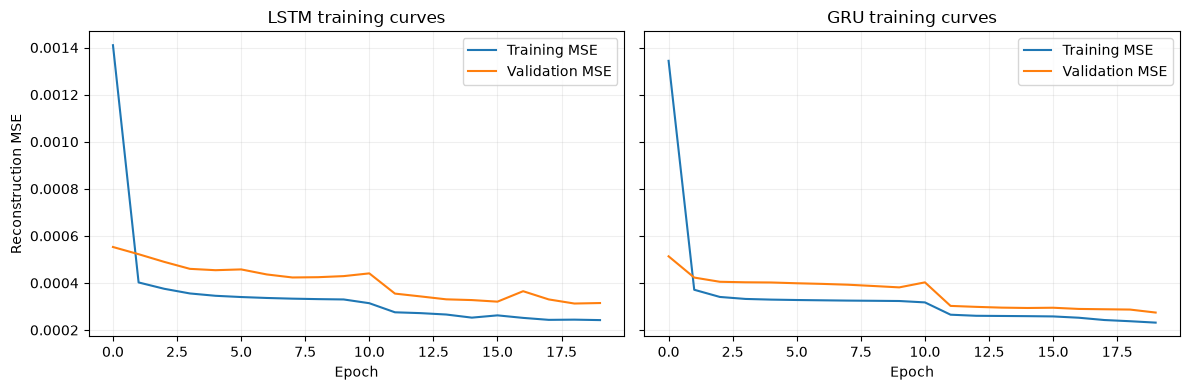

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, name in zip(axes, ["LSTM", "GRU"]):
    ax.plot(histories[name]["loss"], label="Training MSE")
    ax.plot(histories[name]["val_loss"], label="Validation MSE")
    ax.set_title(f"{name} training curves")
    ax.set_xlabel("Epoch")
    ax.legend()

axes[0].set_ylabel("Reconstruction MSE")
plt.tight_layout()
plt.show()

## Convert Reconstruction Errors into Anomaly Alerts

We use a deliberately simple scoring rule:

**Anomaly score = average squared reconstruction error across the KPI features at the final time step of a window.**

Example: the 60-step input window ends at test observation 100. We compare the **30 original KPI values at observation 100** with the **30 reconstructed values** at that same observation.

We use the calibration portion (from the original **training series**) to set an anomaly threshold:

**Threshold = the 99 percentile of calibration anomaly scores at begining.**

Any test score above that threshold is flagged anomalous. **Test labels are never used to set the threshold.** 


In [18]:
def reconstruction_scores(model, windows):
    # Reconstruct each window (shape: windows × 60 × features)
    reconstructed = model.predict(windows, batch_size=PREDICT_BATCH, verbose=0)

    # Use only the final time step of each window for a single-point anomaly score
    # select all the features for the last time step of each window for both actual and reconstructed data
    actual_last = windows[:, -1, :]
    reconstructed_last = reconstructed[:, -1, :]

    # calculate MSE across all KPI features
    scores = np.mean((actual_last - reconstructed_last) ** 2, axis=1)
    return scores, reconstructed_last


runs = {}   # Store results for each model
for name in ["LSTM", "GRU"]:
    model = models[name]

    # Calibration scores determine the threshold
    cal_scores, _ = reconstruction_scores(model, W_CAL)   # get reconstruction scores for calibration windows,no 2nd return value needed
    threshold = np.percentile(cal_scores, THRESHOLD_PERCENTILE)  # compute the threshold(anomaly score) which is the 99.5th percentile of the calibration scores

    # get the alert according to the threshold through W_TEST(test data)
    test_scores, reconstructed_kpis = reconstruction_scores(model, W_TEST)
    alerts = (test_scores > threshold).astype(int)

    runs[name] = {
        "cal_scores": cal_scores,
        "test_scores": test_scores,
        "reconstructed_kpis": reconstructed_kpis,
        "threshold": threshold,
        "alerts": alerts
    }

    print(f"{name}: threshold = {threshold:.6f}, total_alerts = {alerts.sum():,}")





LSTM: threshold = 0.002573, total_alerts = 2,809
GRU: threshold = 0.002577, total_alerts = 1,815


## Visualize Detection Results

The charts below show **where** each model flags an anomaly:

- **Blue line:** Model-generated anomaly score.
- **Orange dashed line:** Detection threshold.
- **Red background:** official labeled anomaly periods in the test data.


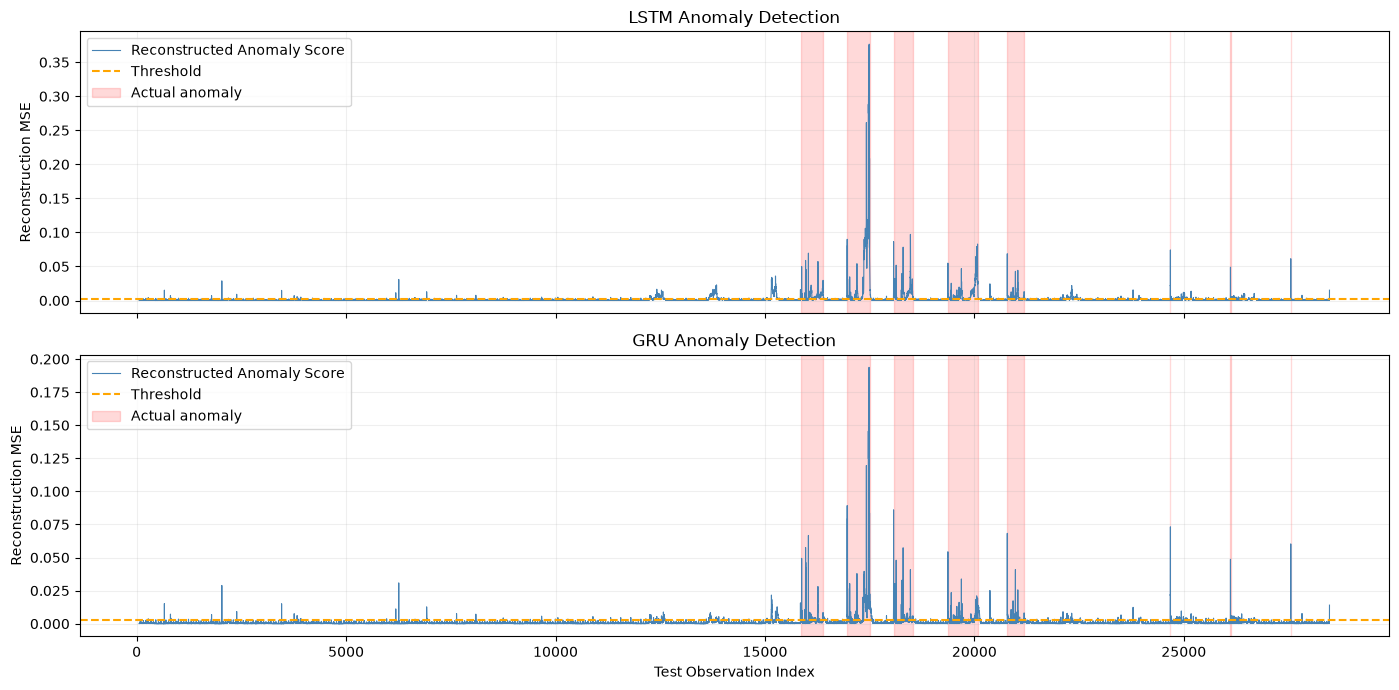

In [20]:
# Test observation indices
test_indices = np.arange(WINDOW_SIZE - 1, len(test)) # return index which from 59 to 28478

# Create two plots: LSTM and GRU
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for ax, name in zip(axes, ["LSTM", "GRU"]):
    scores = runs[name]["test_scores"]
    threshold = runs[name]["threshold"]

    # Plot reconstructed KPI anomaly scores
    ax.plot(test_indices, scores, color="steelblue",
            linewidth=0.8, label="Reconstructed Anomaly Score")

    # Plot detection threshold
    ax.axhline(threshold, color="orange",
               linestyle="--", label="Threshold")

    # Highlight actual anomaly periods
    for i, (start, end) in enumerate(anomaly_periods):
        ax.axvspan(start, end,color="red",alpha=0.15,
            label="Actual anomaly" if i == 0 else None ) # Only label the first span to avoid duplicate legend entries    
        
    ax.set_title(f"{name} Anomaly Detection")
    ax.set_ylabel("Reconstruction MSE")
    ax.legend()

axes[1].set_xlabel("Test Observation Index")

plt.tight_layout()
plt.show()

## Compare Original and Reconstructed KPI Values

The model is not trying to predict the next KPI value. It is **reconstructing an already observed KPI window**.

This plot compares the actual and reconstructed values for **one feature** around the anomaly region. 

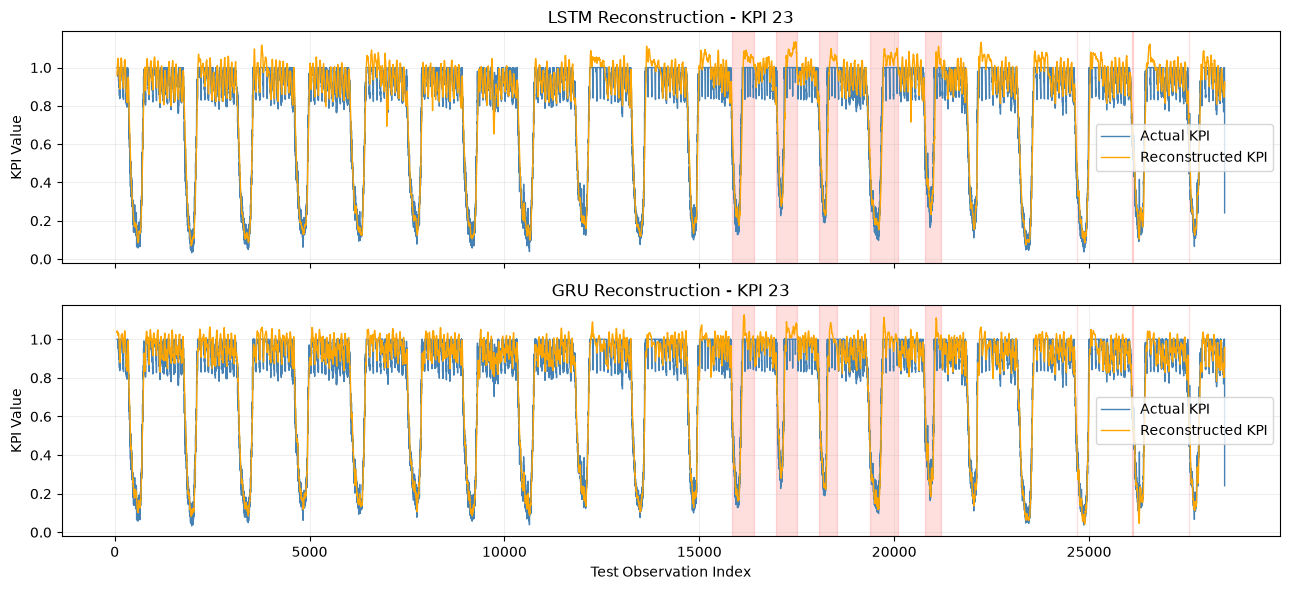

In [21]:
# Select the KPI with the largest standard deviation
feature_index = int(np.argmax(train_data.std(axis=0)))  # select the index of the KPI with the highest standard deviation in the training data, and return its index

# Get the original KPI number
original_kpi_number = np.flatnonzero(keep_columns)[feature_index] + 1

# Actual KPI values
original_kpi = W_TEST[:, -1, feature_index]

# Plot LSTM and GRU reconstruction
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

for ax, name in zip(axes, ["LSTM", "GRU"]):

    # Get reconstructed KPI values
    reconstructed_kpi = runs[name]["reconstructed_kpis"][:, feature_index]

    # Compare actual and reconstructed KPI
    ax.plot(test_indices, original_kpi, label="Actual KPI", color="steelblue", lw=1)
    ax.plot(test_indices, reconstructed_kpi, label="Reconstructed KPI", color="orange", lw=1)

    # Highlight ground-truth anomalies
    for start, end in anomaly_periods:
        ax.axvspan(start, end, color="red", alpha=0.13)

    ax.set_ylabel("KPI Value")
    ax.set_title(f"{name} Reconstruction - KPI {original_kpi_number}")
    ax.legend()

axes[-1].set_xlabel("Test Observation Index")

plt.tight_layout()
plt.show()

## Evaluate LSTM and GRU with the Official Test Labels

For each test observation:

- **True positive (TP):** abnormal observation correctly detected.
- **False positive (FP):** normal observation incorrectly flagged.
- **False negative (FN):** anomaly missed.
- **True negative (TN):** normal observation correctly ignored.

We report **Precision, Recall, F1-score, and a Confusion Matrix**. 
The model and threshold were selected without test labels. We use labels **only here** for final evaluation.

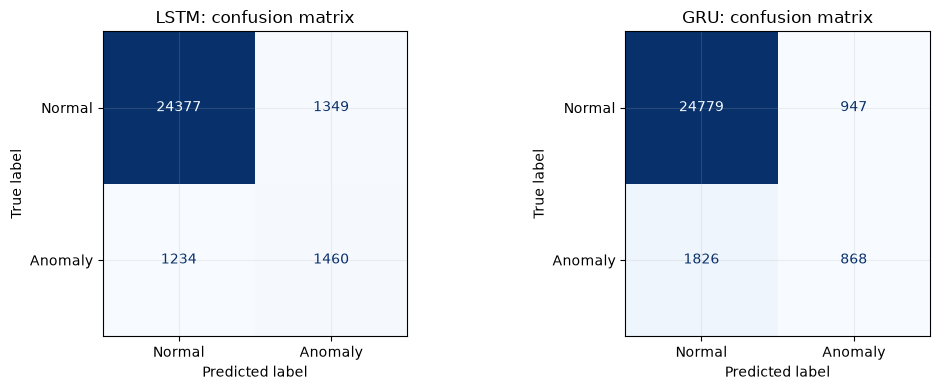

Point-level test-set performance:


,Precision,Recall,F1-score
Model,,,
LSTM,0.5198,0.5419,0.5306
GRU,0.4782,0.3222,0.3850


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay

metrics = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name in zip(axes, ["LSTM", "GRU"]):
    y_pred = runs[name]["alerts"]
    assert len(y_pred) == len(y_true), "Prediction and label lengths must match"

    metrics.append({
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[0, 1],
        display_labels=["Normal", "Anomaly"],
        cmap="Blues", values_format="d", colorbar=False, ax=ax
    )
    ax.set_title(f"{name}: confusion matrix")

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(metrics).set_index("Model")
print("Point-level test-set performance:")
display(results_df.round(4))

## Visualize Model Comparison and Summarize Observations

The final chart compares **Precision, Recall, and F1** directly.
- Higher **Precision** means fewer false alarms among flagged observations.
- Higher **Recall** means fewer missed anomalous observations.
- Higher **F1** balances these two measures.

The present system only detects anomalies from **already observed** KPI values.

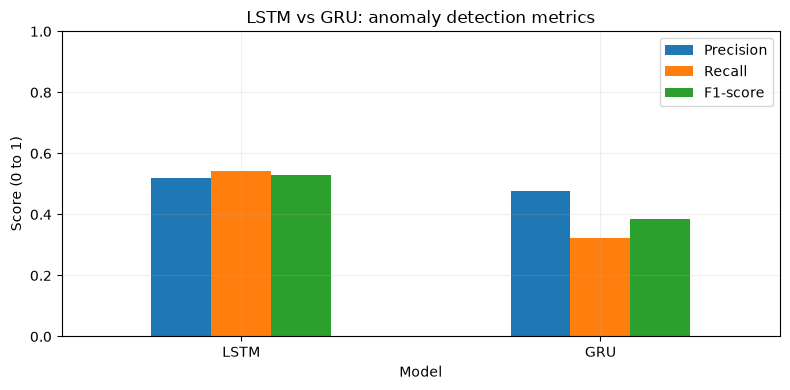

Higher test F1 on this machine: LSTM
This is a result for machine-1-1 and the fixed threshold; it does not prove general superiority.


In [23]:
ax = results_df.plot(kind="bar", figsize=(8, 4), ylim=(0, 1), rot=0)
ax.set_title("LSTM vs GRU: anomaly detection metrics")
ax.set_ylabel("Score (0 to 1)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

winner = results_df["F1-score"].idxmax()
print(f"Higher test F1 on this machine: {winner}")
print(f"This is a result for {MACHINE} and the fixed threshold; it does not prove general superiority.")

## Final Experiment Summary
- Display the hyperparameters used in this experiment and the final detection metrics for LSTM and GRU.

In [ ]:
# Final Summary: Experiment Parameters and Model Performance

# Step 1: Collect predefined parameters
parameters = {
    "WINDOW": WINDOW,
    "UNITS": UNITS,
    "LATENT": LATENT,
    "EPOCHS": EPOCHS,
    "TRAIN_BATCH": TRAIN_BATCH,
    "PREDICT_BATCH": PREDICT_BATCH,
    "LEARNING_RATE": LEARNING_RATE,
    "THRESHOLD_PERCENTILE": THRESHOLD_PERCENTILE
}

# Step 2: Display parameters
print(f"Dataset: {MACHINE}")
print("\nExperiment Parameters:")

display(pd.DataFrame(
    parameters.items(),
    columns=["Parameter", "Value"]
).set_index("Parameter"))

# Step 3: Display model performance
print("\nAnomaly Detection Metrics (Test Data):")

display(results_df[
    ["Precision", "Recall", "F1-score"]
].round(4))

## Conclusion and Limitations

**What this notebook demonstrates**

- Reading and visualizing real, anonymized SMD KPI time series.
- Training **two unsupervised Deep Learning Autoencoders** without anomaly labels.
- Detecting test anomalies using **reconstruction MSE + a calibration threshold**.
- Comparing LSTM and GRU via **Precision, Recall, F1 and confusion matrices**.

**Important limitations**

1. The original SMD training data has **no anomaly labels**; it may contain some unusual behavior.
2. The THRESHOLD_PERCENTILE can be tuned to adjust model. A high threshold can miss anomalies; a low threshold can cause false alarms.
3. This evaluation covers **one SMD machine**, not all 28.
6. This project is **anomaly detection only**. It does **not** attempt early warning or future forecasting.

**Tune the model:** we can change window size, batch size, and latent size, etc. inspect additional machines, or other hyperparameters to tune them.